# 05 · Impacto no negócio

**Autor:** Gabriel Carvalho · **Fase CRISP-DM:** avaliação

Objetivo da etapa: traduzir o desempenho do modelo do notebook 04 em **custo**, escolher o limiar de decisão que minimiza esse custo (no treino, com predições *out-of-fold*) e comparar, no teste, as manutenções **corretiva**, **preventiva por desgaste** e **preditiva**. Fecha com uma análise de sensibilidade à razão entre o custo da falha e o da intervenção.

In [1]:
# Ambiente: coloca src/ no sys.path (o notebook roda a partir de notebooks/ ou da raiz)
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(RAIZ / "src"))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from manutencao import custo as cu
from manutencao.config import DIR_TABELAS
from manutencao.preparacao import carregar_preparado, dividir_treino_teste
from manutencao.util import configurar_graficos, salvar_figura, salvar_tabela

configurar_graficos()

## Modelo de custo

| Situação | O que acontece | Custo |
|---|---|---|
| Alerta e o ciclo ia falhar (VP) | intervenção planejada evita a falha | `intervencao` |
| Alerta e o ciclo não ia falhar (FP) | intervenção desnecessária | `intervencao` |
| Sem alerta e o ciclo falha (FN) | parada não planejada, reparo, refugo | `falha` |
| Sem alerta e sem falha (VN) | nada | 0 |

**Atenção: os valores são hipóteses do grupo, não custos reais de mercado.** O dataset não traz custos. Adotamos `intervencao = R$ 500` e `falha = R$ 5.000` (razão 10). Como só a **razão** falha/intervenção altera as decisões, a última seção varre as razões 2, 5, 10, 20 e 50.

As três estratégias têm os parâmetros escolhidos **no treino** e são medidas **no teste**:

1. **Corretiva**: nunca intervém.
2. **Preventiva**: intervém quando `desgaste_ferramenta_min >= L`; `L` vem de uma grade de 0 a 255 min (passo 5) que minimiza o custo no treino.
3. **Preditiva**: intervém quando `proba >= t`; `t` minimiza o custo nas predições *out-of-fold* do treino.

In [3]:
oof = pd.read_csv(DIR_TABELAS / "04_oof_treino.csv")
pred = pd.read_csv(DIR_TABELAS / "04_predicoes_teste.csv")
treino, teste = dividir_treino_teste(carregar_preparado())
oof = oof.merge(treino[["udi", "desgaste_ferramenta_min"]], on="udi", validate="one_to_one")
pred = pred.merge(teste[["udi", "desgaste_ferramenta_min"]], on="udi", validate="one_to_one")
assert len(oof) == 8000 and len(pred) == 2000
assert (oof["falha"].sum(), pred["falha"].sum()) == (
    int(treino["falha"].sum()),
    int(teste["falha"].sum()),
)
print(
    f"treino: {len(oof)} ciclos, {oof['falha'].sum()} falhas · teste: {len(pred)} ciclos, {pred['falha'].sum()} falhas"
)

treino: 8000 ciclos, 271 falhas · teste: 2000 ciclos, 68 falhas


## Escolha do limiar no treino

O limiar é um parâmetro de decisão. Escolhê-lo olhando o teste contaminaria a medida final, então usamos as probabilidades *out-of-fold* do treino: cada ciclo foi previsto por um modelo que não o viu. O teste só mede o resultado.

In [4]:
custos = cu.Custos()
curva = cu.curva_custo_limiar(oof["falha"], oof["proba"], custos)
t = cu.melhor_limiar(curva)
salvar_tabela(curva, "05_curva_custo_limiar_treino")
print(f"limiar ótimo no treino (OOF): {t:.2f}")
curva.loc[curva["limiar"] == t, ["limiar", "vp", "fp", "fn", "custo_total"]]

limiar ótimo no treino (OOF): 0.23


,limiar,vp,fp,fn,custo_total
22,0.23,228,55,43,356500.0


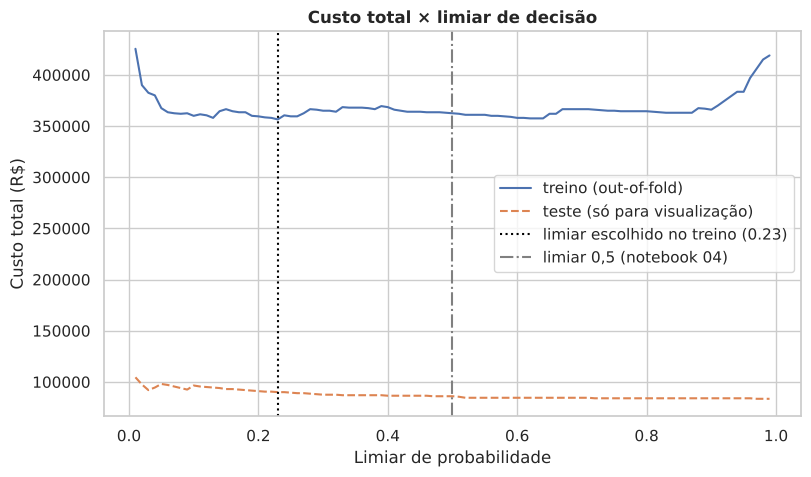

In [5]:
curva_teste = cu.curva_custo_limiar(pred["falha"], pred["proba"], custos)
fig, ax = plt.subplots()
ax.plot(curva["limiar"], curva["custo_total"], label="treino (out-of-fold)")
ax.plot(
    curva_teste["limiar"],
    curva_teste["custo_total"],
    linestyle="--",
    label="teste (só para visualização)",
)
ax.axvline(t, color="black", linestyle=":", label=f"limiar escolhido no treino ({t:.2f})")
ax.axvline(0.5, color="gray", linestyle="-.", label="limiar 0,5 (notebook 04)")
ax.set_xlabel("Limiar de probabilidade")
ax.set_ylabel("Custo total (R$)")
ax.set_title("Custo total × limiar de decisão")
ax.legend()
salvar_figura(fig, "05_curva_custo_limiar")
plt.show()

In [6]:
L = cu.melhor_limite_desgaste(oof["desgaste_ferramenta_min"], oof["falha"], custos)
print(f"limite de desgaste da preventiva (escolhido no treino): {L} min")

limite de desgaste da preventiva (escolhido no treino): 205 min


## Comparação das estratégias no teste

In [7]:
estrategias = pd.DataFrame(
    [
        cu.estrategia_corretiva(pred["falha"], custos),
        cu.estrategia_preventiva(pred["desgaste_ferramenta_min"], pred["falha"], L, custos),
        cu.estrategia_preditiva(pred["proba"], pred["falha"], t, custos),
    ]
)
corretiva = estrategias.loc[estrategias["estrategia"] == "corretiva", "custo_total"].iloc[0]
preventiva = estrategias.loc[estrategias["estrategia"] == "preventiva", "custo_total"].iloc[0]
estrategias["economia_vs_corretiva_pct"] = 100 * (1 - estrategias["custo_total"] / corretiva)
estrategias["economia_vs_preventiva_pct"] = 100 * (1 - estrategias["custo_total"] / preventiva)
salvar_tabela(estrategias, "05_estrategias_teste")
estrategias

,estrategia,parametro,vp,fp,fn,vn,intervencoes,falhas_evitadas,falhas_nao_evitadas,custo_total,custo_por_1000_ciclos,economia_vs_corretiva_pct,economia_vs_preventiva_pct
0,corretiva,-,0,0,68,1932,0,0,68,340000.0,170000.0,0.000000,-8.8
1,preventiva,desgaste >= 205 min,18,107,50,1825,125,18,50,312500.0,156250.0,8.088235,0.0
2,preditiva,proba >= 0.23,57,13,11,1919,70,57,11,90000.0,45000.0,73.529412,71.2


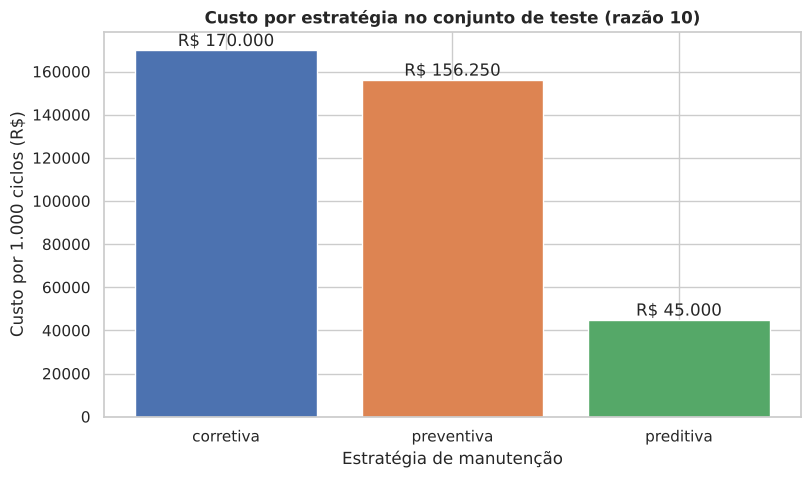

In [8]:
fig, ax = plt.subplots()
barras = ax.bar(
    estrategias["estrategia"], estrategias["custo_por_1000_ciclos"], color=sns.color_palette()[:3]
)
ax.bar_label(
    barras, labels=[f"R$ {v:,.0f}".replace(",", ".") for v in estrategias["custo_por_1000_ciclos"]]
)
ax.set_xlabel("Estratégia de manutenção")
ax.set_ylabel("Custo por 1.000 ciclos (R$)")
ax.set_title("Custo por estratégia no conjunto de teste (razão 10)")
salvar_figura(fig, "05_comparacao_estrategias")
plt.show()

limiar do notebook 04: 0.5


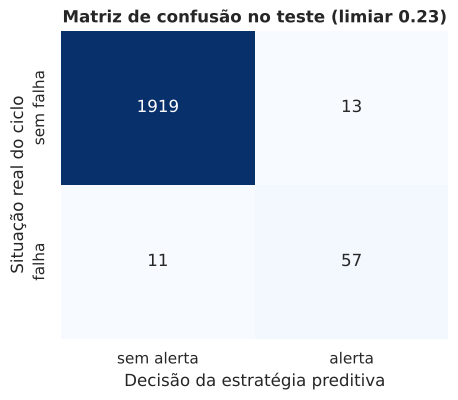

,parametro,vp,fp,fn,vn,custo_total
0,proba >= 0.50,57,5,11,1927,86000.0
1,proba >= 0.23,57,13,11,1919,90000.0


In [9]:
ref = pd.read_csv(DIR_TABELAS / "04_metricas_teste.csv")
print("limiar do notebook 04:", ref["limiar"].iloc[0])
base = cu.estrategia_preditiva(pred["proba"], pred["falha"], float(ref["limiar"].iloc[0]), custos)
otimo = estrategias[estrategias["estrategia"] == "preditiva"].iloc[0]
comparacao = pd.DataFrame([base, otimo.to_dict()])[
    ["parametro", "vp", "fp", "fn", "vn", "custo_total"]
]
fig, ax = plt.subplots(figsize=(5, 4))
mc = [[otimo["vn"], otimo["fp"]], [otimo["fn"], otimo["vp"]]]
sns.heatmap(
    mc,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    cbar=False,
    ax=ax,
    xticklabels=["sem alerta", "alerta"],
    yticklabels=["sem falha", "falha"],
)
ax.set_xlabel("Decisão da estratégia preditiva")
ax.set_ylabel("Situação real do ciclo")
ax.set_title(f"Matriz de confusão no teste (limiar {t:.2f})")
salvar_figura(fig, "05_matriz_confusao_limiar_custo")
plt.show()
comparacao

## Sensibilidade à razão de custos

In [10]:
sens = cu.sensibilidade(
    oof["falha"],
    oof["proba"],
    oof["desgaste_ferramenta_min"],
    pred["falha"],
    pred["proba"],
    pred["desgaste_ferramenta_min"],
)
salvar_tabela(sens, "05_sensibilidade")
sens.pivot(
    index="razao_falha_intervencao", columns="estrategia", values="custo_por_1000_ciclos"
).round(0)

estrategia,corretiva,preditiva,preventiva
razao_falha_intervencao,,,
2,34000.0,20000.0,34000.0
5,85000.0,28500.0,84500.0
10,170000.0,45000.0,156250.0
20,340000.0,73500.0,253750.0
50,850000.0,122250.0,500000.0


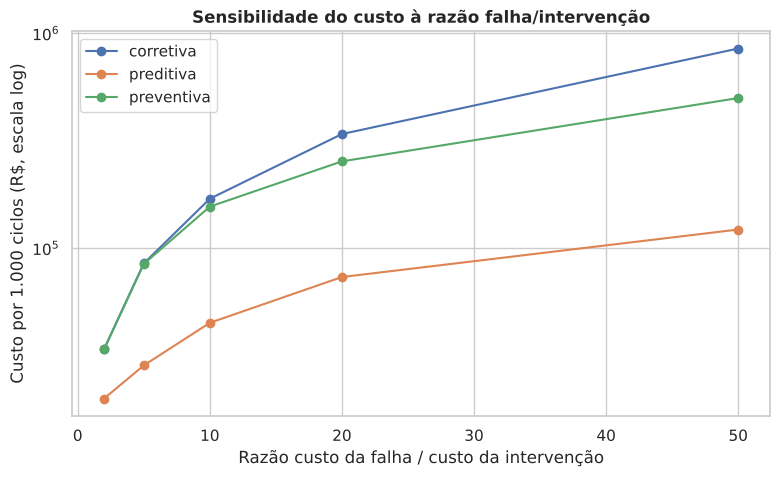

In [11]:
fig, ax = plt.subplots()
for nome, g in sens.groupby("estrategia"):
    ax.plot(g["razao_falha_intervencao"], g["custo_por_1000_ciclos"], marker="o", label=nome)
ax.set_yscale("log")
ax.set_xlabel("Razão custo da falha / custo da intervenção")
ax.set_ylabel("Custo por 1.000 ciclos (R$, escala log)")
ax.set_title("Sensibilidade do custo à razão falha/intervenção")
ax.legend()
salvar_figura(fig, "05_sensibilidade")
plt.show()

In [12]:
# Parâmetros escolhidos no treino em cada razão
sens[sens["estrategia"] != "corretiva"][
    ["razao_falha_intervencao", "estrategia", "parametro", "intervencoes", "falhas_nao_evitadas"]
]

,razao_falha_intervencao,estrategia,parametro,intervencoes,falhas_nao_evitadas
1,2,preventiva,desgaste >= 250 min,0,68
2,2,preditiva,proba >= 0.91,58,11
4,5,preventiva,desgaste >= 225 min,18,64
5,5,preditiva,proba >= 0.64,59,11
7,10,preventiva,desgaste >= 205 min,125,50
8,10,preditiva,proba >= 0.23,70,11
10,20,preventiva,desgaste >= 200 min,175,42
11,20,preditiva,proba >= 0.06,94,10
13,50,preventiva,desgaste >= 0 min,2000,0
14,50,preditiva,proba >= 0.01,139,7


## Conclusões

Todos os valores em R$ são **hipóteses** (intervenção R$ 500, falha R$ 5.000, razão 10), não custos reais.

- **Preditiva × corretiva (razão 10).** No teste (2.000 ciclos, 68 falhas), a corretiva custa R$ 170.000 por 1.000 ciclos e a preditiva, R$ 45.000: economia de 73,5 % (`05_estrategias_teste.csv`). A preditiva evita 57 das 68 falhas com 70 intervenções (13 delas desnecessárias).
- **Preditiva × preventiva (razão 10).** A preventiva por desgaste, com limite de 205 min escolhido no treino, custa R$ 156.250 por 1.000 ciclos, só 8,1 % abaixo da corretiva: faz 125 intervenções, evita 18 falhas e deixa passar 50. A preditiva custa 71,2 % menos que ela. O desgaste só explica o TWF; HDF, PWF e OSF não dependem dele.
- **Sensibilidade.** A preditiva é a mais barata em todas as razões testadas (`05_sensibilidade.csv`). Na razão 2 custa R$ 20.000 contra R$ 34.000 das outras duas (a preventiva ótima não intervém nunca, limite de 250 min). Na razão 50 custa R$ 122.250 contra R$ 500.000 da preventiva, que passa a intervir em todos os ciclos (limite de 0 min), e R$ 850.000 da corretiva.
- **Limiar cai quando a falha encarece.** O limiar escolhido no treino vai de 0,91 (razão 2) a 0,64 (5), 0,23 (10), 0,06 (20) e 0,01 (50): quanto mais cara a falha em relação ao alarme, mais vale aceitar alarmes falsos para não perder uma falha.
- **Limiar de custo × limiar 0,5 do notebook 04.** No teste, o limiar 0,23 detecta as mesmas 57 falhas que o 0,5 e gera 8 alarmes falsos a mais (13 contra 5): custo de R$ 90.000 contra R$ 86.000 (R$ 45.000 contra R$ 43.000 por 1.000 ciclos). Ou seja, nesta amostra de teste o limiar escolhido no treino ficou ligeiramente pior que 0,5; a diferença é de alguns alarmes, dentro do ruído de um teste com 68 falhas, e o limiar não foi ajustado ao teste (seria vazamento).
- **O que ainda passa.** Restam 11 falhas não evitadas no teste. Conforme `04_recall_por_modo.csv`, o modelo detecta 100 % de HDF, PWF e OSF; as perdas vêm de TWF (1 de 10 detectado), RNF (0 de 4, aleatório por construção) e 2 falhas sem modo registrado.
- **Limitações.** Custos hipotéticos, dataset sintético e uma única divisão treino/teste; só a conclusão qualitativa (preditiva muito abaixo das demais enquanto a razão for maior que 1) deve ser levada adiante, não os valores absolutos.